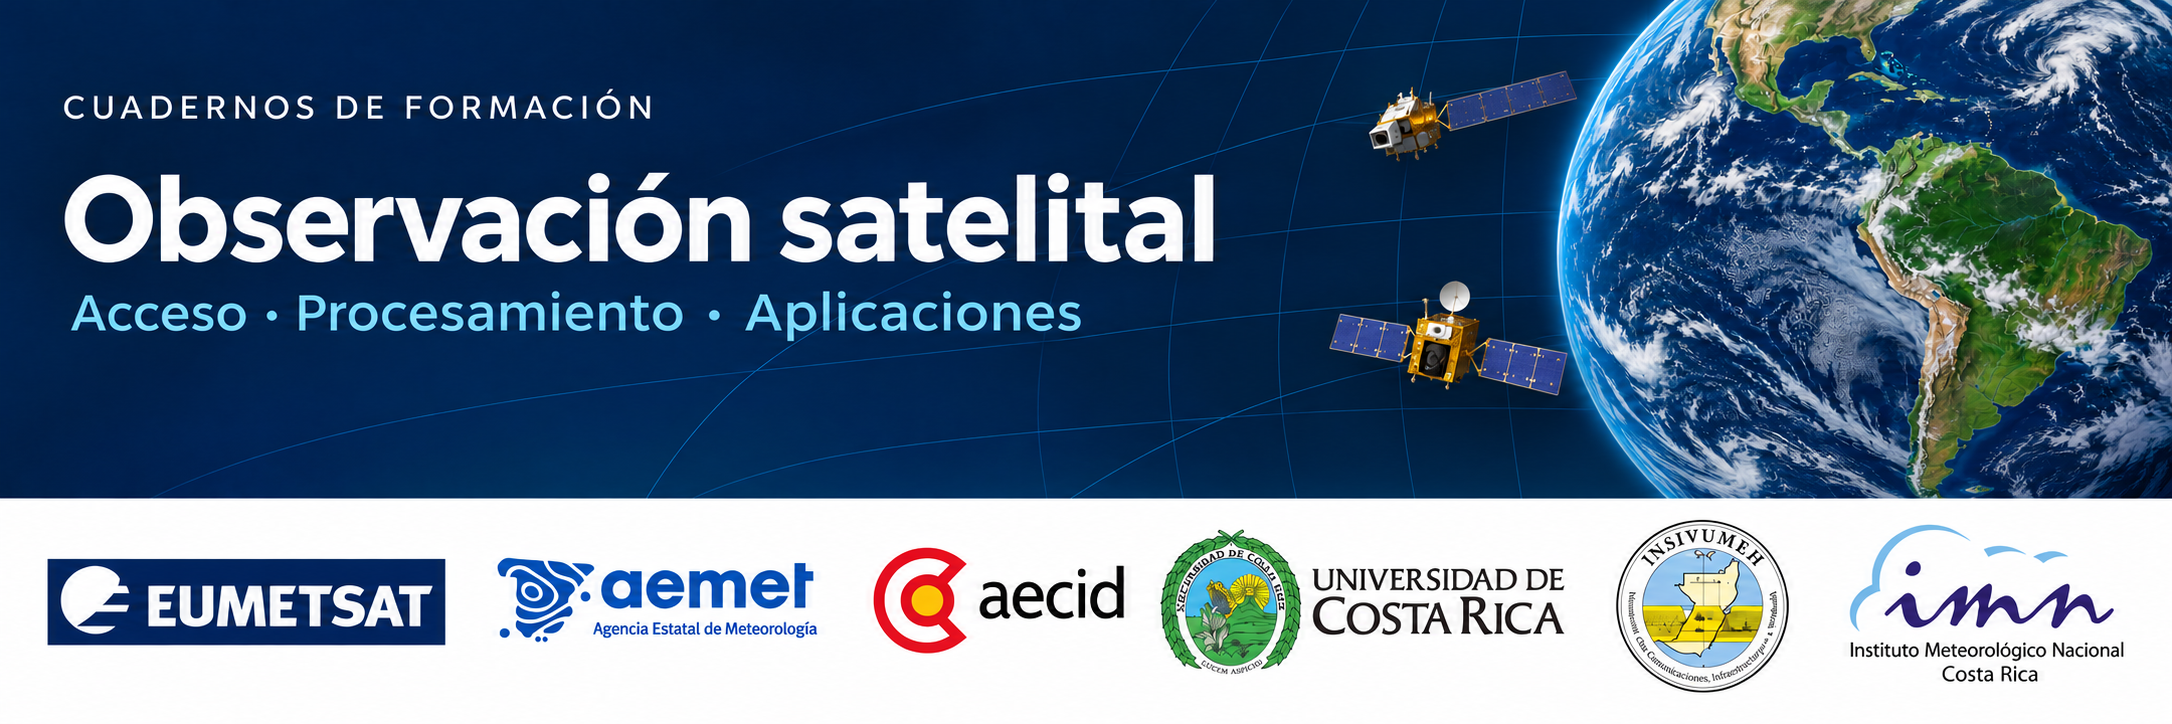

**PRODUCTOS Y APLICACIONES DE LOS SATÉLITES METEOROLÓGICOS**  
Fase presencial · Uruguay · Noviembre de 2026  
AEMET y EUMETSAT, con apoyo de AECID

# 08 · NDVI · Diez años de vegetación

*Del dato satelital a una serie de tiempo que podemos actualizar*

| Ficha de la práctica | Detalle |
| :--- | :--- |
| Área temática | Vegetación |
| Datos y acceso | NASA ORNL DAAC TESViS · MODIS/Terra MOD13Q1 |
| Entorno | Google Colab o Jupyter / Anaconda de 64 bits |

> **Guía de trabajo:** lea el caso y sus requisitos; ejecute las celdas en orden; revise cada resultado antes de avanzar. Después, cambie un parámetro a la vez y conserve la procedencia de los datos.

**Recorrido:** comprender el caso · preparar el acceso · procesar · interpretar · guardar y reutilizar.

---


## Antes de comenzar · cuentas y acceso

**Para este cuaderno:** Ninguna cuenta del proveedor: esta práctica utiliza la API pública TESViS de ORNL DAAC.

| Cuenta o servicio | Cuándo la necesita | Registro |
| :--- | :--- | :--- |
| Google | Solo si utiliza Colab o Google Drive; no se requiere para la ejecución local en Jupyter / Anaconda. | [Crear cuenta de Google](https://accounts.google.com/signup) |
| NASA ORNL DAAC · TESViS | Ninguna cuenta del proveedor: esta práctica utiliza la API pública TESViS de ORNL DAAC. | No necesita registrarse |

**Crear una cuenta es un proceso guiado y sencillo.** Si ya utiliza Gmail o Google Drive, puede usar esa misma cuenta de Google. También puede crearla con un correo que ya tenga, sin abrir un Gmail nuevo: [guía en español](https://support.google.com/accounts/answer/27441?hl=es).

No necesita cuenta NASA Earthdata ni Google Earth Engine para la ruta utilizada aquí, tanto en Muestra incluida como en En línea.

Antes de la sesión, compruebe que puede iniciar sesión y complete la verificación por correo si el portal la solicita. Cada participante utiliza su propia cuenta. Introduzca las credenciales únicamente cuando el cuaderno lo indique; no las escriba en celdas que vaya a compartir.

---


## Presentación del caso

**Pregunta del caso:** ¿cómo cambia la vegetación de una región y cuándo se aparta de su comportamiento estacional?

Vamos a obtener valores científicos de **MODIS/Terra MOD13Q1, colección 6.1**, a través del servicio público **NASA ORNL DAAC TESViS**. Construiremos una serie regional, revisaremos su calidad y compararemos un año con una referencia histórica. Terminaremos reproduciendo el análisis desde una terminal.

**Para empezar:** ejecutá las celdas en orden. El modo inicial usa una muestra real incluida: permite aprender sin esperar una descarga histórica durante la clase. Luego elegí **En línea** para consultar NASA con los mismos parámetros o para trabajar en tu país. No requiere cuenta Earthdata ni Earth Engine.

Este caso se guarda por separado de SST, IMERG y SPEI. En Colab, Google Drive conserva la caché y los resultados entre sesiones. La primera instalación de paquetes y el montaje de Drive sí necesitan conexión.


---

## 1 · Qué vamos a observar

| Elemento | Selección del caso |
|---|---|
| Región | Entorno del punto 32,8° S, 56,52° O, en Uruguay |
| Extensión solicitada | 5 km a cada lado; aproximadamente 10 × 10 km, ajustados a la malla |
| Producto | MOD13Q1.061 · NDVI Terra/MODIS |
| Resolución | 250 m nominales; celda sinusoidal de unos 231,66 m |
| Muestreo temporal | Composiciones de 16 días; 23 por año |
| Serie incluida | Enero de 2015 a diciembre de 2024 · 230 composiciones |
| Referencia estacional | 2015–2021; al menos 5 años aceptados por composición |
| Año para comparar | 2023; editable |
| Datos adicionales | Fiabilidad del píxel y calidad detallada |

La muestra contiene **41 × 41 píxeles por fecha**, en su malla nativa. Es un estudio de una región pequeña dentro de Uruguay, **no un promedio de todo el país**. Reducir el área permite conservar la resolución y limitar el tráfico.

El rectángulo incluye superficies clasificadas como agua: la máscara fija conserva **743 de 1681 píxeles como tierra**. La serie y su cobertura se calculan sobre esa superficie terrestre, no sobre todo el rectángulo. El mapa permite verlo.

El NDVI usa el contraste entre infrarrojo cercano y rojo: `(NIR − rojo) / (NIR + rojo)`. Es adimensional. Un cambio puede relacionarse con fenología, cosecha, suelo, agua, nubes residuales o estrés de la vegetación. **Una anomalía negativa no demuestra por sí sola sequía.**

Cada fecha identifica el inicio nominal de una composición. Los píxeles pueden proceder de distintos días dentro de ese intervalo; no son observaciones diarias ni una media de 16 mediciones. El último intervalo del año es más corto.


In [1]:
#@title Preparar Python
import sys, importlib.util, subprocess
PAQUETES = {"requests":"requests>=2.31,<3", "numpy":"numpy>=1.24,<3", "pandas":"pandas>=2.0,<3", "matplotlib":"matplotlib>=3.7,<4", "xarray":"xarray>=2023.1", "netCDF4":"netCDF4>=1.6,<2", "pyproj":"pyproj>=3.5,<4"}
faltantes = [paquete for modulo,paquete in PAQUETES.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable,"-m","pip","install","--quiet",*faltantes])
print("Dependencias disponibles. Python:",sys.version.split()[0])

Dependencias disponibles. Python: 3.13.18


---

## 2 · Elegir región y modo de acceso

**Muestra incluida:** utiliza las tres bandas reales de Uruguay 2015–2024 guardadas dentro del notebook. Permite modificar calidad, cobertura, referencia y año de comparación; para cambiar ubicación o ampliar fechas, elegí **En línea**.

**En línea:** consulta las fechas publicadas, comprueba la colección y descarga bloques de hasta diez fechas. Reutiliza bloques completos de la caché. Si falla la conexión, conserva los bloques terminados y avisa; al ejecutar nuevamente continúa lo pendiente.

**Solo caché:** exige que los datos solicitados ya estén guardados en la carpeta de trabajo. No realiza consultas de red. La muestra incluida utiliza su propia subcarpeta para distinguirla de las descargas personales.

`KM = 0` selecciona un píxel. Para otro país, empezá con una región terrestre pequeña, por ejemplo `LAT = 10.4`, `LON = -84.4` en Costa Rica. La máscara de tierra se toma de una fecha fija; conservá esa fecha para comparar y actualizar la serie sobre la misma superficie.


In [2]:
#@title Parámetros del caso
MODO = "Muestra incluida" #@param ["Muestra incluida", "En línea", "Solo caché"]
MONTAR_DRIVE = True #@param {type:"boolean"}
NOMBRE = "Uruguay_centro" #@param {type:"string"}
LAT = -32.8 #@param {type:"number"}
LON = -56.52 #@param {type:"number"}
KM = 5 #@param {type:"integer"}
INICIO = "2015-01-01" #@param {type:"date"}
FIN = "2024-12-31" #@param {type:"date"}
REF_INICIO = 2015 #@param {type:"integer"}
REF_FIN = 2021 #@param {type:"integer"}
CALIDAD = "Buena" #@param ["Buena", "Buena y marginal"]
COBERTURA_MINIMA = 0.70 #@param {type:"number"}
ANIO_COMPARAR = 2023 #@param {type:"integer"}
FECHA_MAPA = "2023-01-01" #@param {type:"date"}
FECHA_TIERRA = "2015-01-01" #@param {type:"date"}
FORZAR_DESCARGA = False #@param {type:"boolean"}

In [3]:
#@title Conectar Drive y crear la carpeta independiente
from pathlib import Path
import importlib.util
EN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if EN_COLAB and MONTAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/Taller_Uruguay/NDVI_MODIS_ORNL")
else:
    BASE = Path.cwd()/"NDVI_MODIS_ORNL"
BASE.mkdir(parents=True, exist_ok=True)
print("Carpeta de este caso:",BASE)

Mounted at /content/drive
Carpeta de este caso: /content/drive/MyDrive/Taller_Uruguay/NDVI_MODIS_ORNL


---

## 3 · Abrir los recursos del caso

La siguiente celda contiene los módulos Python y la muestra comprimida. Verifica su integridad antes de usarlos. El código queda disponible como archivos `.py` legibles y se incluye en el paquete final para terminal. No descarga imágenes de Worldview: trabaja con NDVI y calidad numéricos.


In [4]:
#@title Recursos del caso: ejecutar una vez (código y muestra real incluidos)
import base64, hashlib, io, zipfile, sys, importlib
RECURSO_B64 = '...'
recurso = base64.b64decode(RECURSO_B64)
assert hashlib.sha256(recurso).hexdigest() == '2682e3776351bcc5426d6029ab944bb63c61dd20fe5e236864f915f39cf631e1', "El recurso incluido está incompleto o alterado."
recursos = zipfile.ZipFile(io.BytesIO(recurso))
CODIGO = BASE/"codigo"
CODIGO.mkdir(parents=True,exist_ok=True)
for nombre in ("ndvi_core.py","ndvi_plots.py","ndvi_caso.py"):
    (CODIGO/nombre).write_bytes(recursos.read("codigo/"+nombre))
if str(CODIGO) not in sys.path: sys.path.insert(0,str(CODIGO))
importlib.invalidate_caches()
import ndvi_core, ndvi_plots
importlib.reload(ndvi_core); importlib.reload(ndvi_plots)
from ndvi_core import configurar, cargar, analizar, exportar, parametros, BANDAS, API, PRODUCTO
from ndvi_plots import graficar
print("Código disponible:",CODIGO)

Código disponible: /content/drive/MyDrive/Taller_Uruguay/NDVI_MODIS_ORNL/codigo


In [5]:
#@title Configurar y obtener los datos
import json
PARAMETROS = dict(nombre=NOMBRE,lat=LAT,lon=LON,km=KM,inicio=INICIO,fin=FIN,ref_inicio=REF_INICIO,ref_fin=REF_FIN,calidad=CALIDAD,cobertura=COBERTURA_MINIMA,anio=ANIO_COMPARAR,fecha_mapa=FECHA_MAPA,fecha_tierra=FECHA_TIERRA)
base_activa = BASE
modo_api = MODO
if MODO == "Muestra incluida":
    if (LAT,LON,KM)!=(-32.8,-56.52,5) or not ("2015-01-01"<=INICIO<=FIN<="2024-12-31") or FECHA_TIERRA!="2015-01-01":
        raise ValueError("La muestra corresponde a Uruguay, KM=5, 2015–2024, con máscara del 01/01/2015. Para otra región o período use En línea.")
    if FORZAR_DESCARGA:raise ValueError("Desactive FORZAR_DESCARGA para usar la muestra incluida.")
    base_activa = BASE/"muestra_incluida"
    # Solo se extraen los cuatro archivos esperados del recurso verificado.
    for miembro in recursos.namelist():
        if miembro.startswith("muestra/cache/") and miembro.rsplit("/",1)[-1] in {"catalogo.json.gz","ndvi.json.gz","fiabilidad.json.gz","qa.json.gz"}:
            ruta=base_activa/Path(miembro).relative_to("muestra")
            ruta.parent.mkdir(parents=True,exist_ok=True)
            if not ruta.exists():ruta.write_bytes(recursos.read(miembro))
    modo_api = "Solo caché"
cfg = configurar(base_activa,**PARAMETROS)
print(f"{PRODUCTO}.061 · {NOMBRE} · {INICIO} a {FIN} · {MODO}")
print(f"Centro: ({LAT}, {LON}); distancia a cada lado: {KM} km. Resolución nativa.")
ds,fuente = cargar(cfg,modo_api,FORZAR_DESCARGA)
if MODO=="Muestra incluida":fuente["origen"]="Muestra real incluida de NASA ORNL DAAC"
print("Dimensiones:",dict(ds.sizes))
print("Fechas publicadas/esperadas:",fuente["fechas_publicadas"],"/",fuente["fechas_esperadas"])
print("Solicitudes nuevas:",fuente["solicitudes_nuevas"])
print(f"Respuestas nuevas decodificadas: {fuente['bytes_respuestas_decodificadas']/1024**2:.2f} MiB (no mide la compresión de red).")
print("Colección confirmada:",fuente["catalogo"]["evidencia_coleccion"])
print("Caché:",cfg["cache"])

MOD13Q1.061 · Uruguay_centro · 2015-01-01 a 2024-12-31 · Muestra incluida
Centro: (-32.8, -56.52); distancia a cada lado: 5 km. Resolución nativa.
Dimensiones: {'time': 230, 'y': 41, 'x': 41}
Fechas publicadas/esperadas: 230 / 230
Solicitudes nuevas: 0
Respuestas nuevas decodificadas: 0.00 MiB (no mide la compresión de red).
Colección confirmada: MOD13Q1.A2015001.h13v12.061.2021317055611.250m_16_days_NDVI
Caché: /content/drive/MyDrive/Taller_Uruguay/NDVI_MODIS_ORNL/muestra_incluida/cache/2844be33506657


---

## 4 · Entender y aplicar la calidad

El dato almacenado se multiplica por **0,0001**. Se conserva el rango científico −0,2 a 1; un cero válido no se trata como dato ausente. El relleno −3000 se excluye.

| Control | Criterio aplicado en este ejercicio |
|---|---|
| Fiabilidad | `0` en Buena; `0` o `1` en Buena y marginal |
| Calidad detallada | MODLAND 0 o 1; utilidad ≤10; aerosol distinto de alto |
| Condiciones adversas | Sin banderas de nube adyacente, nube mixta, nieve ni sombra |
| Superficie | Tierra en la máscara fija y en la fecha observada |
| Serie regional | Al menos el porcentaje elegido de píxeles terrestres válidos |

Es un filtro conservador y explícito del ejercicio. Aceptar píxeles marginales no elimina los demás controles. La máscara fija procede del indicador tierra/agua de `VI_Quality` en `FECHA_TIERRA`; no es una clasificación de cultivos ni una máscara administrativa.

**Cobertura válida = píxeles terrestres aceptados / píxeles de la máscara fija.** Como las celdas tienen igual área, el promedio aritmético sirve para esta región. Los píxeles disponibles pueden cambiar entre fechas: hay que revisar también la cobertura y el mapa de calidad. Las fechas bajo el umbral quedan con `ndvi_media` vacío, aunque `media_validos` conserva el promedio provisional para diagnóstico.


In [6]:
#@title Calcular la serie, la referencia y las anomalías
ds,serie,estacional,anual = analizar(ds,cfg)
salida = exportar(ds,serie,estacional,anual,cfg,fuente)
from IPython.display import display
print(f"{int(serie.aceptada.sum())}/{len(serie)} composiciones aceptadas; {int(ds.tierra.sum())} píxeles en la máscara terrestre.")
print("Referencia:",REF_INICIO,"a",REF_FIN,"· mínimo 5 años válidos por composición.")
if estacional.n_anios.max()<5:print("No hay años suficientes para la referencia; las anomalías quedan vacías.")
display(serie[["fecha","ndvi_media","cobertura","n_validos","referencia","anomalia_ndvi"]].head(12))
print("Resultados:",salida)

214/230 composiciones aceptadas; 743 píxeles en la máscara terrestre.
Referencia: 2015 a 2021 · mínimo 5 años válidos por composición.


,fecha,ndvi_media,cobertura,n_validos,referencia,anomalia_ndvi
0,2015-01-01,0.672354,1.000000,743,0.599289,0.073065
1,2015-01-17,0.699359,0.740242,550,0.594014,0.105345
2,2015-02-02,0.593222,0.868102,645,0.558950,0.034272
3,2015-02-18,0.553662,0.842530,626,0.592770,-0.039108
4,2015-03-06,0.593951,0.773890,575,0.591522,0.002429
5,2015-03-22,0.473509,0.855989,636,0.578043,-0.104534
6,2015-04-07,0.447233,0.857335,637,0.571537,-0.124305
7,2015-04-23,0.468315,0.878869,653,0.594687,-0.126372
8,2015-05-09,0.489655,0.767160,570,0.624059,-0.134404
9,2015-05-25,NaN,0.452221,336,0.615034,NaN


Resultados: /content/drive/MyDrive/Taller_Uruguay/NDVI_MODIS_ORNL/muestra_incluida/resultados/Uruguay_centro_c8e331e8d0


---

## 5 · Leer las gráficas antes de concluir

La referencia compara la misma posición dentro del ciclo anual: composición 1 con composición 1, y así hasta 23. Su banda P10–P90 describe la variabilidad entre los años de referencia, no la incertidumbre instrumental. Es una **referencia del ejercicio de siete años**, no una normal climatológica de treinta años.

La anomalía se expresa en unidades de NDVI: **observación − media de referencia**. Para un análisis operativo, ampliá el período de referencia y mantenelo fijo al incorporar nuevos datos. Los cambios de uso del suelo o de manejo requieren una interpretación adicional.


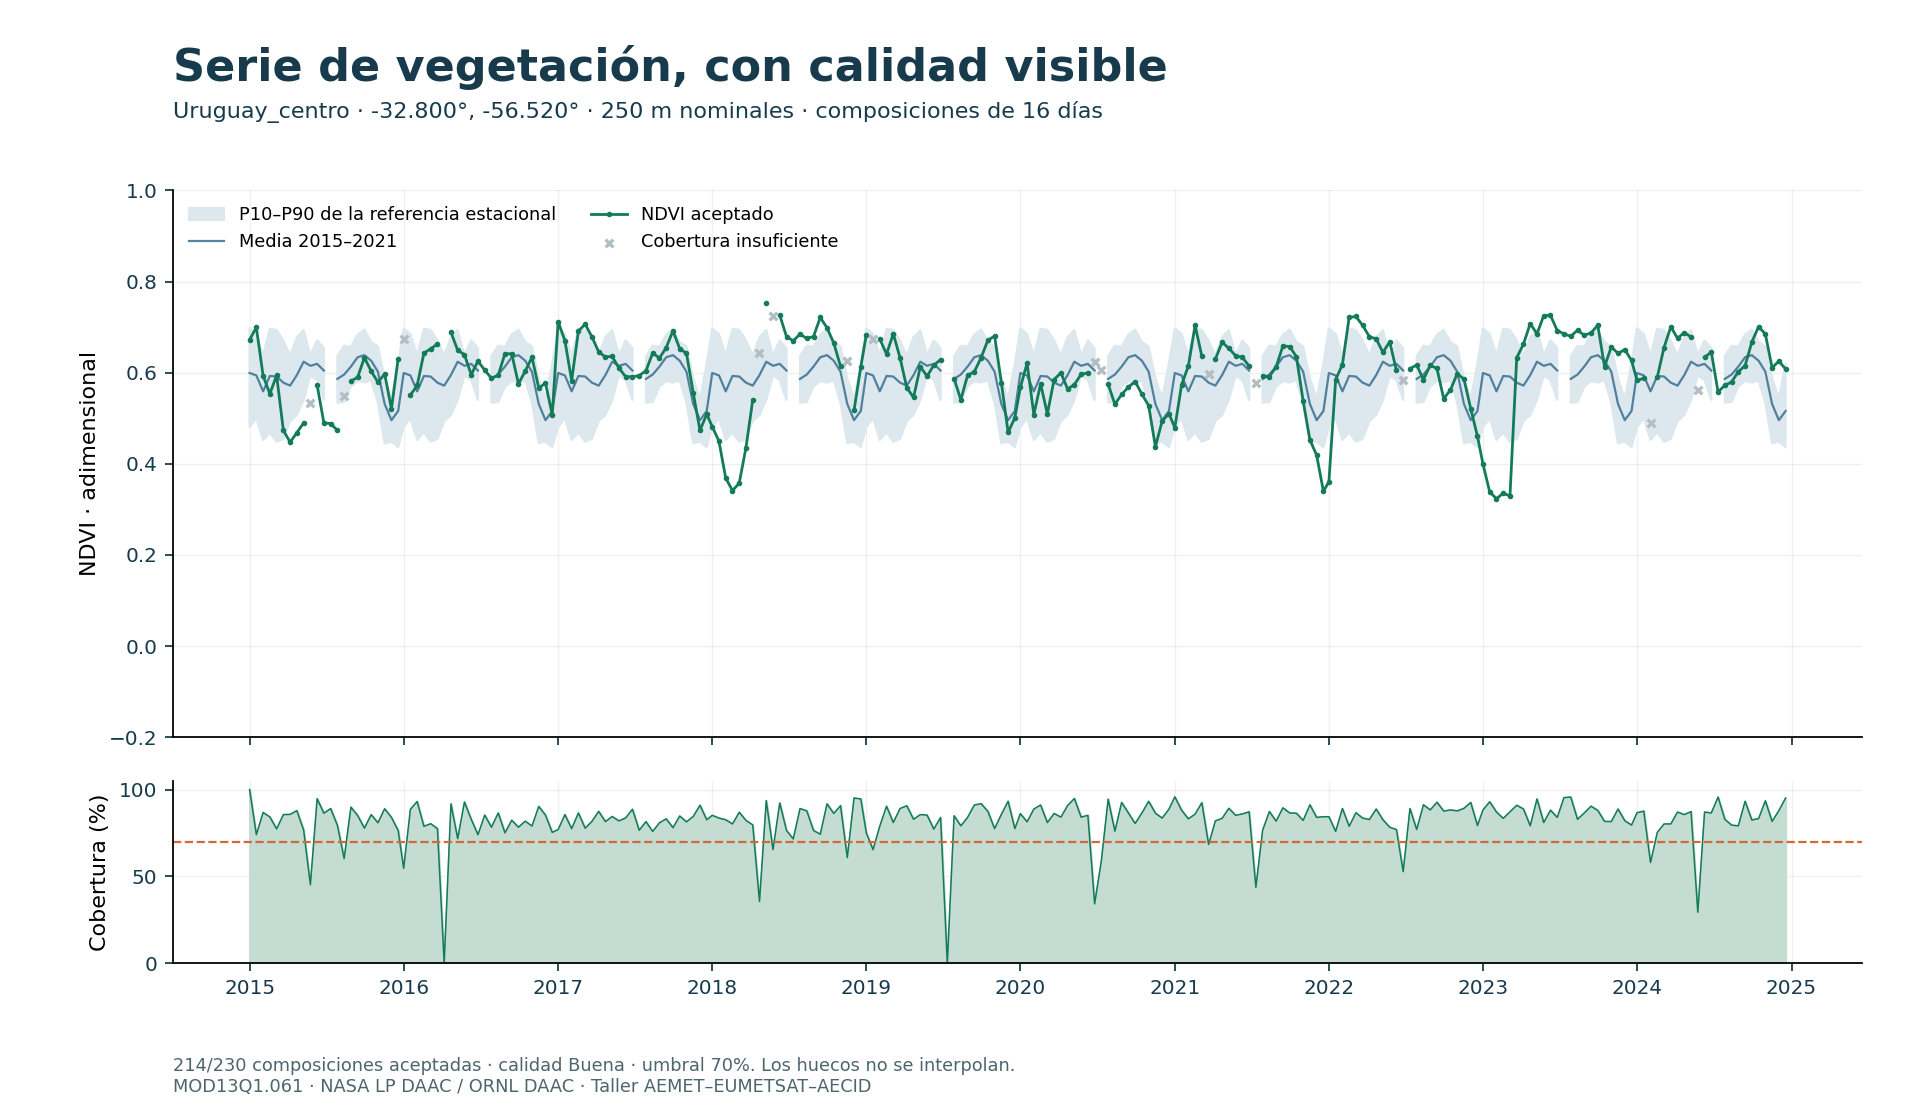

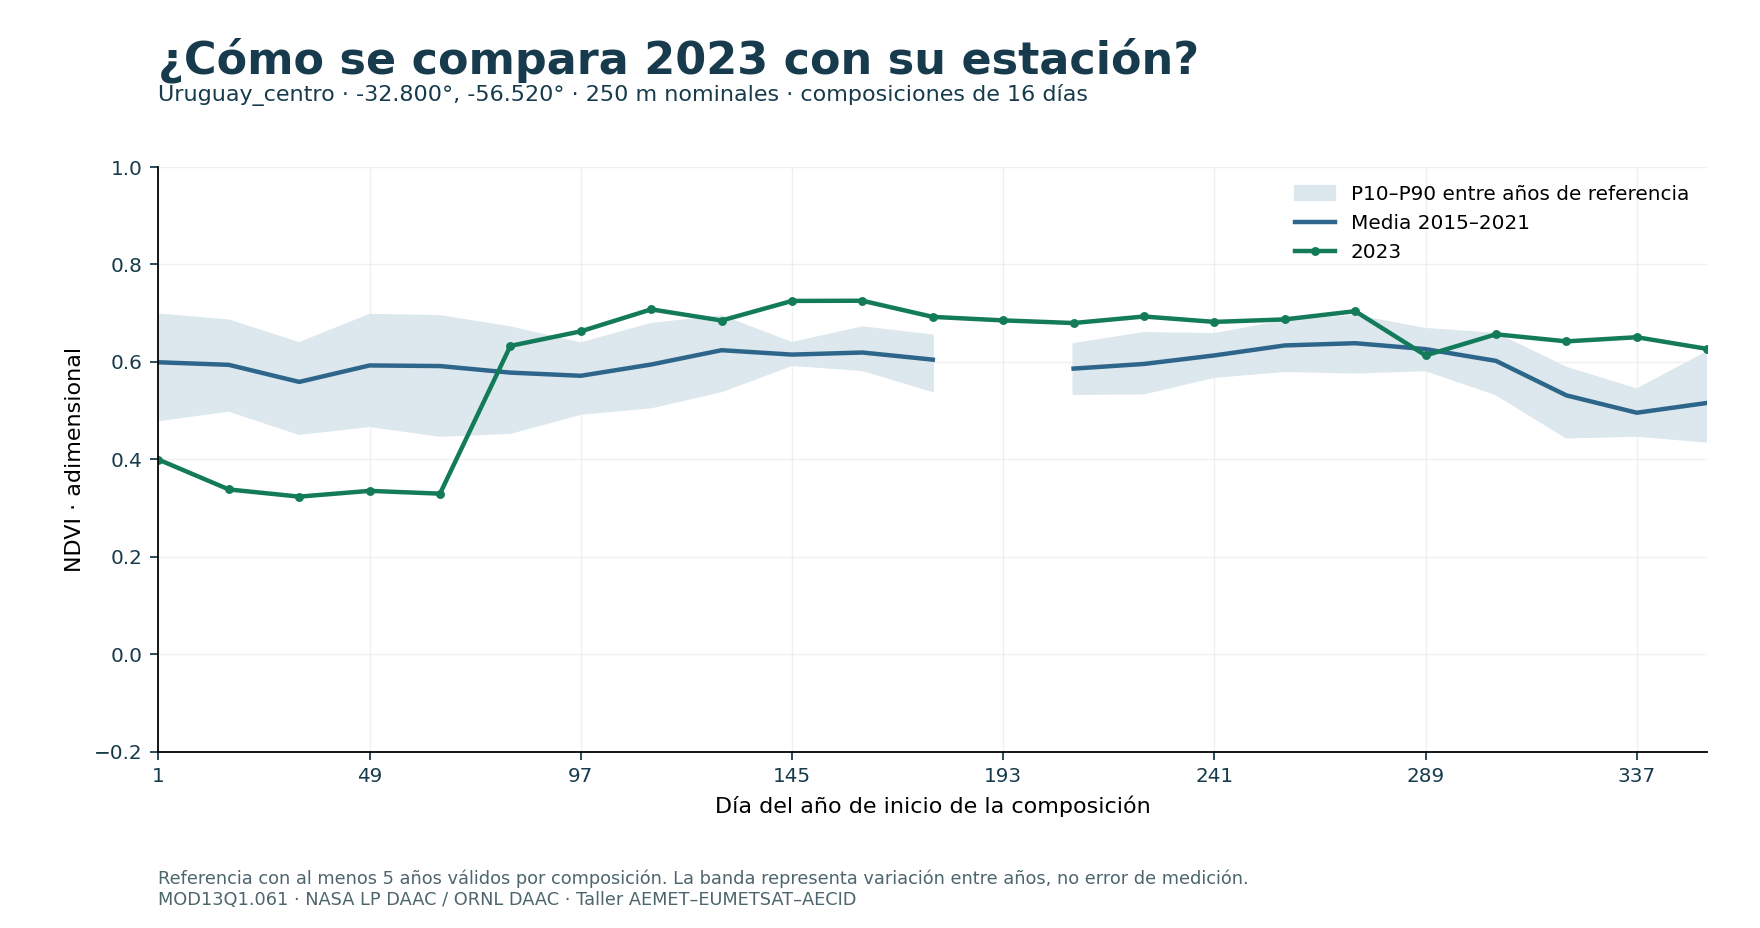

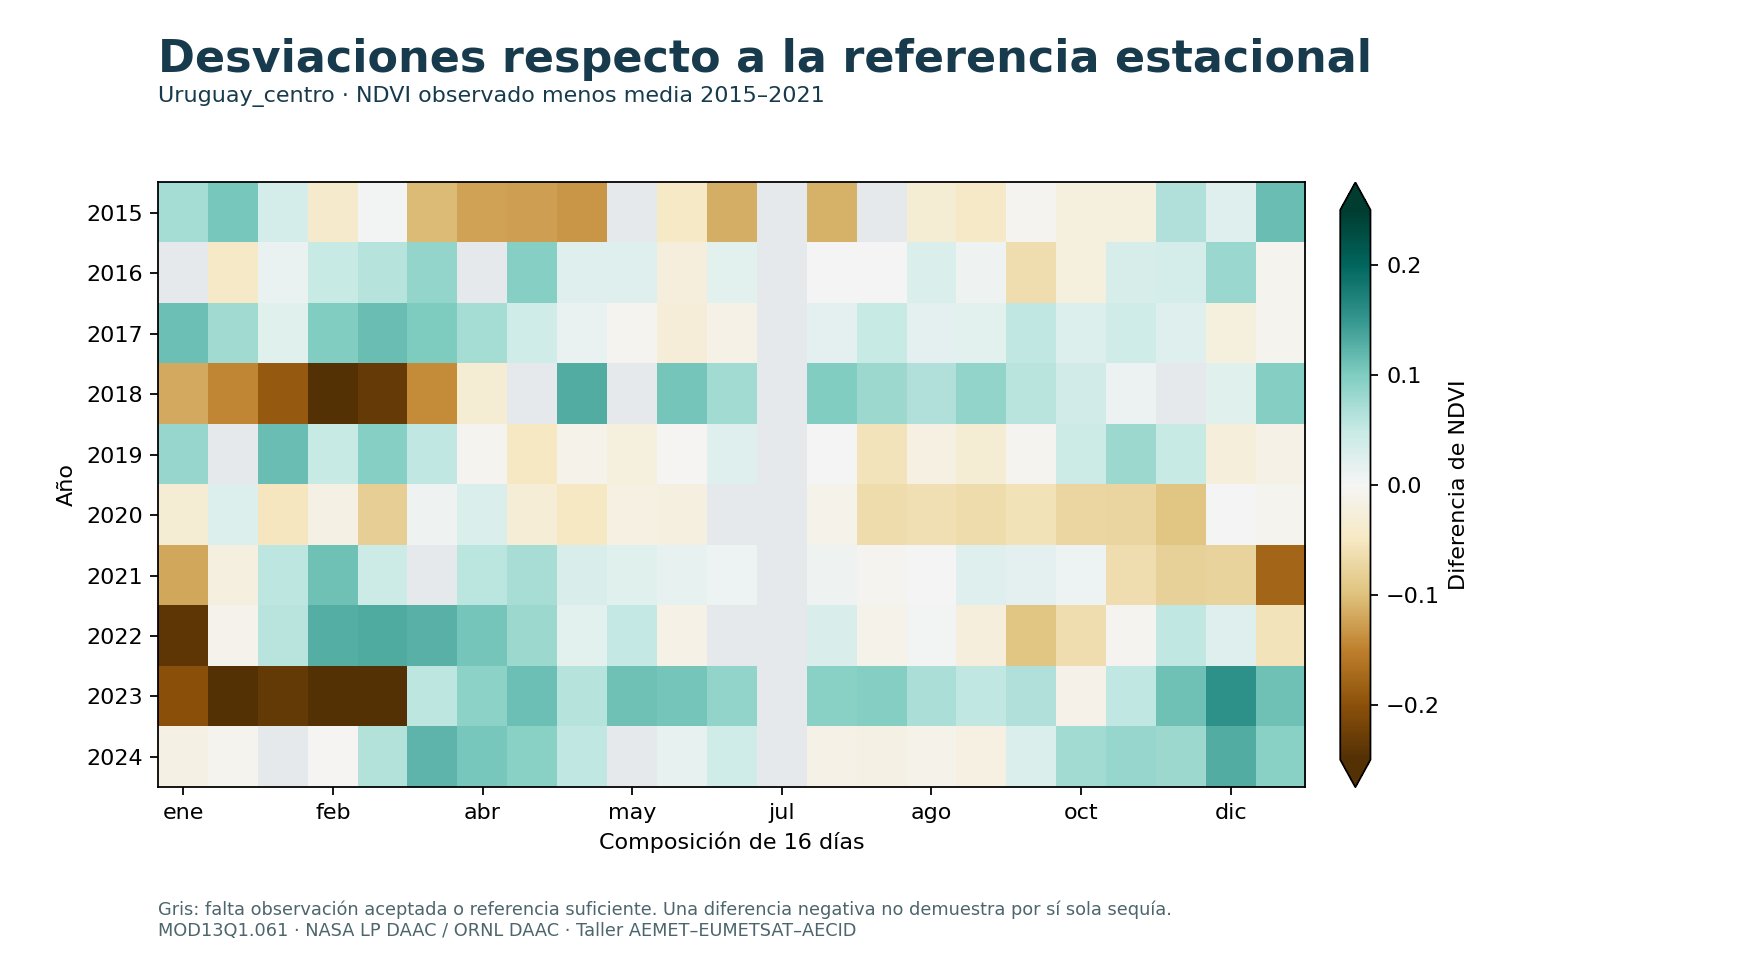

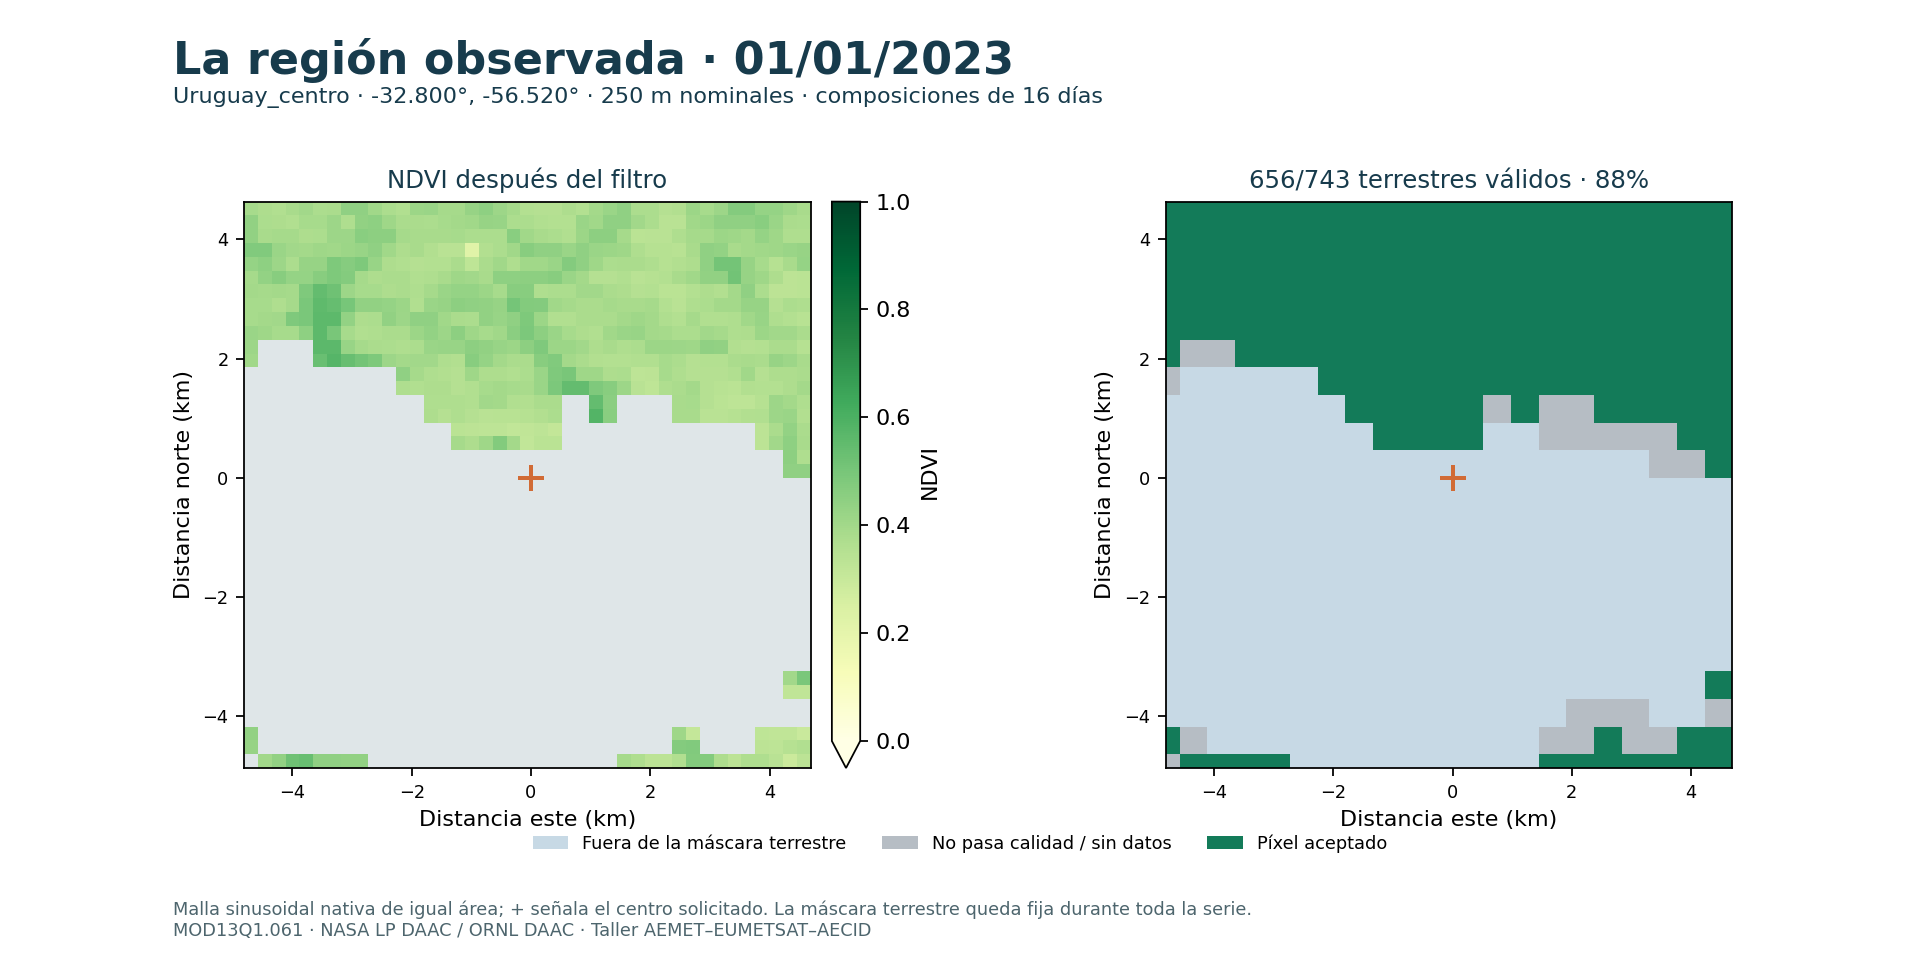

In [7]:
#@title Serie histórica, comparación estacional, anomalías y mapa
from IPython.display import Image
figuras = graficar(ds,serie,estacional,anual,cfg)
for figura in figuras:display(Image(filename=str(figura),width=1000))

In [8]:
#@title Comparar años sin ocultar datos ausentes
display(anual)
print("media_composiciones_disponibles es la media de las composiciones aceptadas, no una media diaria anual.")
print("anio_completo solo es verdadero si se incluyen y aceptan las 23 composiciones.")
print("Para comparar años incompletos, revisá la distribución estacional de los huecos.")

,composiciones_en_intervalo,composiciones_aceptadas,cobertura_media,media_composiciones_disponibles,anio_completo
anio,,,,,
2015,23,21,0.818363,0.559551,False
2016,23,21,0.775821,0.610211,False
2017,23,23,0.823746,0.626165,True
2018,23,20,0.809761,0.583512,False
2019,23,21,0.799345,0.606406,False
2020,23,21,0.833051,0.553711,False
2021,23,21,0.835099,0.587545,False
2022,23,22,0.836503,0.604003,False
2023,23,23,0.868922,0.603458,True


media_composiciones_disponibles es la media de las composiciones aceptadas, no una media diaria anual.
anio_completo solo es verdadero si se incluyen y aceptan las 23 composiciones.
Para comparar años incompletos, revisá la distribución estacional de los huecos.


---

## 6 · Del notebook a una terminal

Aquí se utiliza la API de ORNL mediante `requests` o `curl`. **Data Tailor y EUMDAC corresponden al caso EUMETSAT**, y no descargan este producto de NASA. La habilidad transferible es la misma: seleccionar, pedir un recorte, comprobar calidad, guardar y automatizar.

La siguiente celda muestra una solicitud de una fecha y una banda. Es suficiente para examinar el acceso, pero la serie completa necesita las tres bandas y todos los bloques. El script del paquete final hace ese trabajo con exactamente las mismas funciones del notebook.


In [9]:
#@title Ver una petición HTTP y su equivalente en PowerShell
import requests
fecha_ejemplo=cfg["fechas"][0:1]
params=parametros(cfg,BANDAS["ndvi"],fecha_ejemplo)
url=requests.Request("GET",f"{API}/{PRODUCTO}/subset",params=params).prepare().url
print("URL de una fecha y una banda:",url,sep="\n")
print("\nPowerShell · una sola línea:")
print(f'curl.exe --fail --retry 2 --connect-timeout 15 --max-time 90 -H "Accept: application/json" "{url}" -o "ndvi_ejemplo.json"')
print("\nPython equivalente (opcional; no se ejecuta otra descarga aquí):")
print("respuesta = requests.get(url, headers={'Accept':'application/json'}, timeout=(15,60))")
print("respuesta.raise_for_status(); datos = respuesta.json()")

URL de una fecha y una banda:
https://modis.ornl.gov/rst/api/v1/MOD13Q1/subset?latitude=-32.8&longitude=-56.52&startDate=A2015001&endDate=A2015001&kmAboveBelow=5&kmLeftRight=5&band=250m_16_days_NDVI

PowerShell · una sola línea:
curl.exe --fail --retry 2 --connect-timeout 15 --max-time 90 -H "Accept: application/json" "https://modis.ornl.gov/rst/api/v1/MOD13Q1/subset?latitude=-32.8&longitude=-56.52&startDate=A2015001&endDate=A2015001&kmAboveBelow=5&kmLeftRight=5&band=250m_16_days_NDVI" -o "ndvi_ejemplo.json"

Python equivalente (opcional; no se ejecuta otra descarga aquí):
respuesta = requests.get(url, headers={'Accept':'application/json'}, timeout=(15,60))
respuesta.raise_for_status(); datos = respuesta.json()


**Reproducir en Anaconda o Python de 64 bits:** descargá y descomprimí el ZIP de la siguiente celda. Abrí una terminal en esa carpeta y ejecutá cada comando en una sola línea:

```powershell
python -m pip install -r requirements.txt
python ndvi_caso.py --modo cache
```

El paquete incluye la caché de la región seleccionada, por lo que el segundo comando reproduce los resultados sin consultar NASA. Para descargar o actualizar:

```powershell
python ndvi_caso.py --modo linea
```

Editá `configuracion_cli.json` para cambiar región, intervalo, calidad o referencia. Al cambiar ubicación se utiliza otra caché. Para ampliar la serie, modificá `fin` y conservá `fecha_tierra` y la referencia histórica; se reutilizan los bloques completos ya guardados. El historial disponible se consulta por ubicación. Si el servidor falla, el programa se detiene y conserva lo terminado; no cambia de producto.

Este flujo puede ejecutarse después con el Programador de tareas de Windows o cron. Antes de automatizarlo, verificá el resultado manualmente para tu región. MOD13Q1 es un producto compuesto con demora de publicación; no es un indicador de condiciones en tiempo real.


In [ ]:
#@title Crear el paquete reproducible con datos, scripts y resultados
import zipfile,json,platform,importlib.metadata
REQUISITOS="requests>=2.31,<3\nnumpy>=1.24,<3\npandas>=2.0,<3\nmatplotlib>=3.7,<4\nxarray>=2023.1\nnetCDF4>=1.6,<2\npyproj>=3.5,<4\n"
LEEME="""CASO NDVI · Curso Productos y aplicaciones de los satélites meteorológicos
AEMET y EUMETSAT con apoyo de AECID · Uruguay

Abrí la terminal en esta carpeta. Cada comando va en una sola línea:
python -m pip install -r requirements.txt
python ndvi_caso.py --modo cache

Para consultar NASA y completar datos:
python ndvi_caso.py --modo linea

Editá configuracion_cli.json para otra región/intervalo. La API no requiere clave.
La caché incluida corresponde a los parámetros del notebook. No alterés sus archivos.
Los resultados originales están en resultados_notebook; los nuevos, en datos/resultados.
CSV: escala aplicada, calidad, cobertura y anomalías. NetCDF: datos crudos y filtrados.
Conservá referencia y fecha_tierra al actualizar. No interpretar una anomalía negativa
como diagnóstico independiente de sequía. Consultá calidad y cobertura.
Fuente: https://modis.ornl.gov/data/modis_webservice.html
Producto: https://ladsweb.modaps.eosdis.nasa.gov/missions-and-measurements/products/MOD13Q1
"""
paquete=BASE/"NDVI_reproducible_CLI.zip"
versiones={p:importlib.metadata.version(p) for p in ("requests","numpy","pandas","matplotlib","xarray","netCDF4","pyproj")}
with zipfile.ZipFile(paquete,"w",zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for nombre in ("ndvi_core.py","ndvi_plots.py","ndvi_caso.py"):z.write(CODIGO/nombre,nombre)
    z.writestr("configuracion_cli.json",json.dumps(PARAMETROS,ensure_ascii=False,indent=2))
    z.writestr("requirements.txt",REQUISITOS)
    z.writestr("LEEME.txt",LEEME)
    z.writestr("versiones_ejecutadas.json",json.dumps({"python":platform.python_version(),"paquetes":versiones},indent=2))
    for p in sorted(cfg["cache"].glob("*.json.gz")):z.write(p,"datos/cache/"+cfg["cache"].name+"/"+p.name)
    for p in sorted(salida.iterdir()):
        if p.is_file():z.write(p,"resultados_notebook/"+p.name)
print(f"Paquete listo: {paquete.name} · {paquete.stat().st_size/1024**2:.2f} MiB")
if EN_COLAB:
    from google.colab import files
    files.download(str(paquete))
else:
    from IPython.display import FileLink
    display(FileLink(str(paquete)))

---

## 7 · Actividad y salida operativa

1. Describí el ciclo estacional y dos períodos con anomalías. ¿Coinciden con buena cobertura?
2. Cambiá **Buena** por **Buena y marginal**, ejecutá desde la celda de configuración de datos y compará cobertura y curva. ¿Cuánto cambia la conclusión?
3. Elegí otra región terrestre de tu país, empezá con `KM=0` o `KM=2`, activá **En línea** y comprobá que cambian las coordenadas y la caché.
4. Descargá el paquete y reproducí los CSV desde una terminal. Luego ampliá `fin`, conservando la referencia, y verificá que se añaden observaciones.

Un resultado útil debe conservar: producto y colección, ubicación, período, fecha de consulta, criterio de calidad, cobertura válida y referencia. Esos elementos se exportan junto con la serie. Los huecos se mantienen visibles y no se mezclan sensores ni colecciones de forma automática.

**Si algo falla:** un timeout puede resolverse reejecutando la descarga; una caché incompleta exige **En línea**; un mapa omitido requiere elegir una fecha nominal presente en `serie_ndvi.csv`; una referencia vacía requiere más años aceptados. Si hay un error de integridad, conservá la copia afectada y retirala de la carpeta indicada antes de volver a descargar. Para volver al ejemplo del curso, seleccioná **Muestra incluida** y restaurá sus parámetros.

### Fuentes y documentación

- [API pública TESViS de ORNL DAAC](https://modis.ornl.gov/data/modis_webservice.html), incluidos ejemplos Python y curl. Servicio: DOI [10.3334/ORNLDAAC/1600](https://doi.org/10.3334/ORNLDAAC/1600).
- [Documentación de los recortes y formatos](https://modis.ornl.gov/documentation.html).
- [MOD13Q1: ficha de NASA LAADS DAAC](https://ladsweb.modaps.eosdis.nasa.gov/missions-and-measurements/products/MOD13Q1).
- [Guía oficial MOD13, colección 6.1](https://modis-land.gsfc.nasa.gov/pdf/MOD13_User_Guide_V61.pdf), interpretación y calidad.

**Alcance:** material docente para construir series reproducibles de una región. La muestra conserva valores satelitales reales, no simulados. Los parámetros de calidad y referencia están expuestos para discutirlos y adaptarlos al uso previsto.
